In [1]:
import numpy as np
from scipy import stats
#
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
#
import shapefile
from shapely.geometry import shape
import shapely.vectorized
## this next library contains some helper functions for reshaping FATES variables into easier to work with dimensions
import ctsm_py
import ctsm_py.fates_xarray_funcs as fa       
#
import textwrap
from cmcrameri import cm
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader


ERROR 1: PROJ: proj_create_from_database: Open of /global/homes/j/jkowalcz/.conda/envs/myenv/share/proj failed


In [2]:
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['figure.autolayout'] = False
plt.rcParams['font.size'] = 16
##plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 300

In [3]:
min_lat_plotting = -22.
max_lat_plotting = 12.
min_lon_plotting = 360.-82.
max_lon_plotting = 360.-42.

geog_range_plotting = [min_lon_plotting, max_lon_plotting, min_lat_plotting, max_lat_plotting]


In [4]:
# Shapefile for Amazon ecoregion
Amazon_shapefile='/global/homes/j/jkowalcz/shapefileamazonecoregionwwf/amazon_ecolola.shp'

In [5]:
# read in FATES output
fates_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/SummaryFiles/'
fates_tag='hydro_comp_bmort_kmax_tune_sapflow_kmax3_5xHR_fixSLA_vcmax40.55_fixHR_branch'
fates_file=fates_tag+'.elm.h0.cat.nc'
fates = xr.open_dataset(fates_path+fates_file)

In [6]:
def make_shapefile_mask(shapefile_path,dataset):
    r = shapefile.Reader(shapefile_path)
    polygon = shape(r.shapes()[0])

    # Standardize longitudes to the -180 to 180 range 
    lon_standardized = ((dataset.lon.values + 180) % 360) - 180

    #Create a 2D grid of your coordinates automatically
    lon_2d, lat_2d = np.meshgrid(lon_standardized, dataset.lat.values)

    #Vectorized polygon check 
    mask_numpy = shapely.vectorized.contains(polygon, lon_2d, lat_2d)

    #Convert it back into a xarray DataArray matching given dataset
    Mask = xr.DataArray(
        mask_numpy.astype(int), 
        coords=[dataset.lat, dataset.lon], 
        dims=["lat", "lon"]
    )

    return Mask

In [7]:
fates_Amazon_mask=make_shapefile_mask(Amazon_shapefile,fates)

In [26]:
#  number of plants per m2 per year
hf_mort=fa.scpf_to_scls_by_pft(fates.FATES_MORTALITY_HYDRAULIC_SZPF,fates)

# plants per m2
nplants=fa.scpf_to_scls_by_pft(fates.FATES_NPLANT_SZPF,fates)

In [27]:
hf_mort_norm=hf_mort.sum(dim='fates_levscls').mean(dim='time')/nplants.sum(dim='fates_levscls').mean(dim='time')

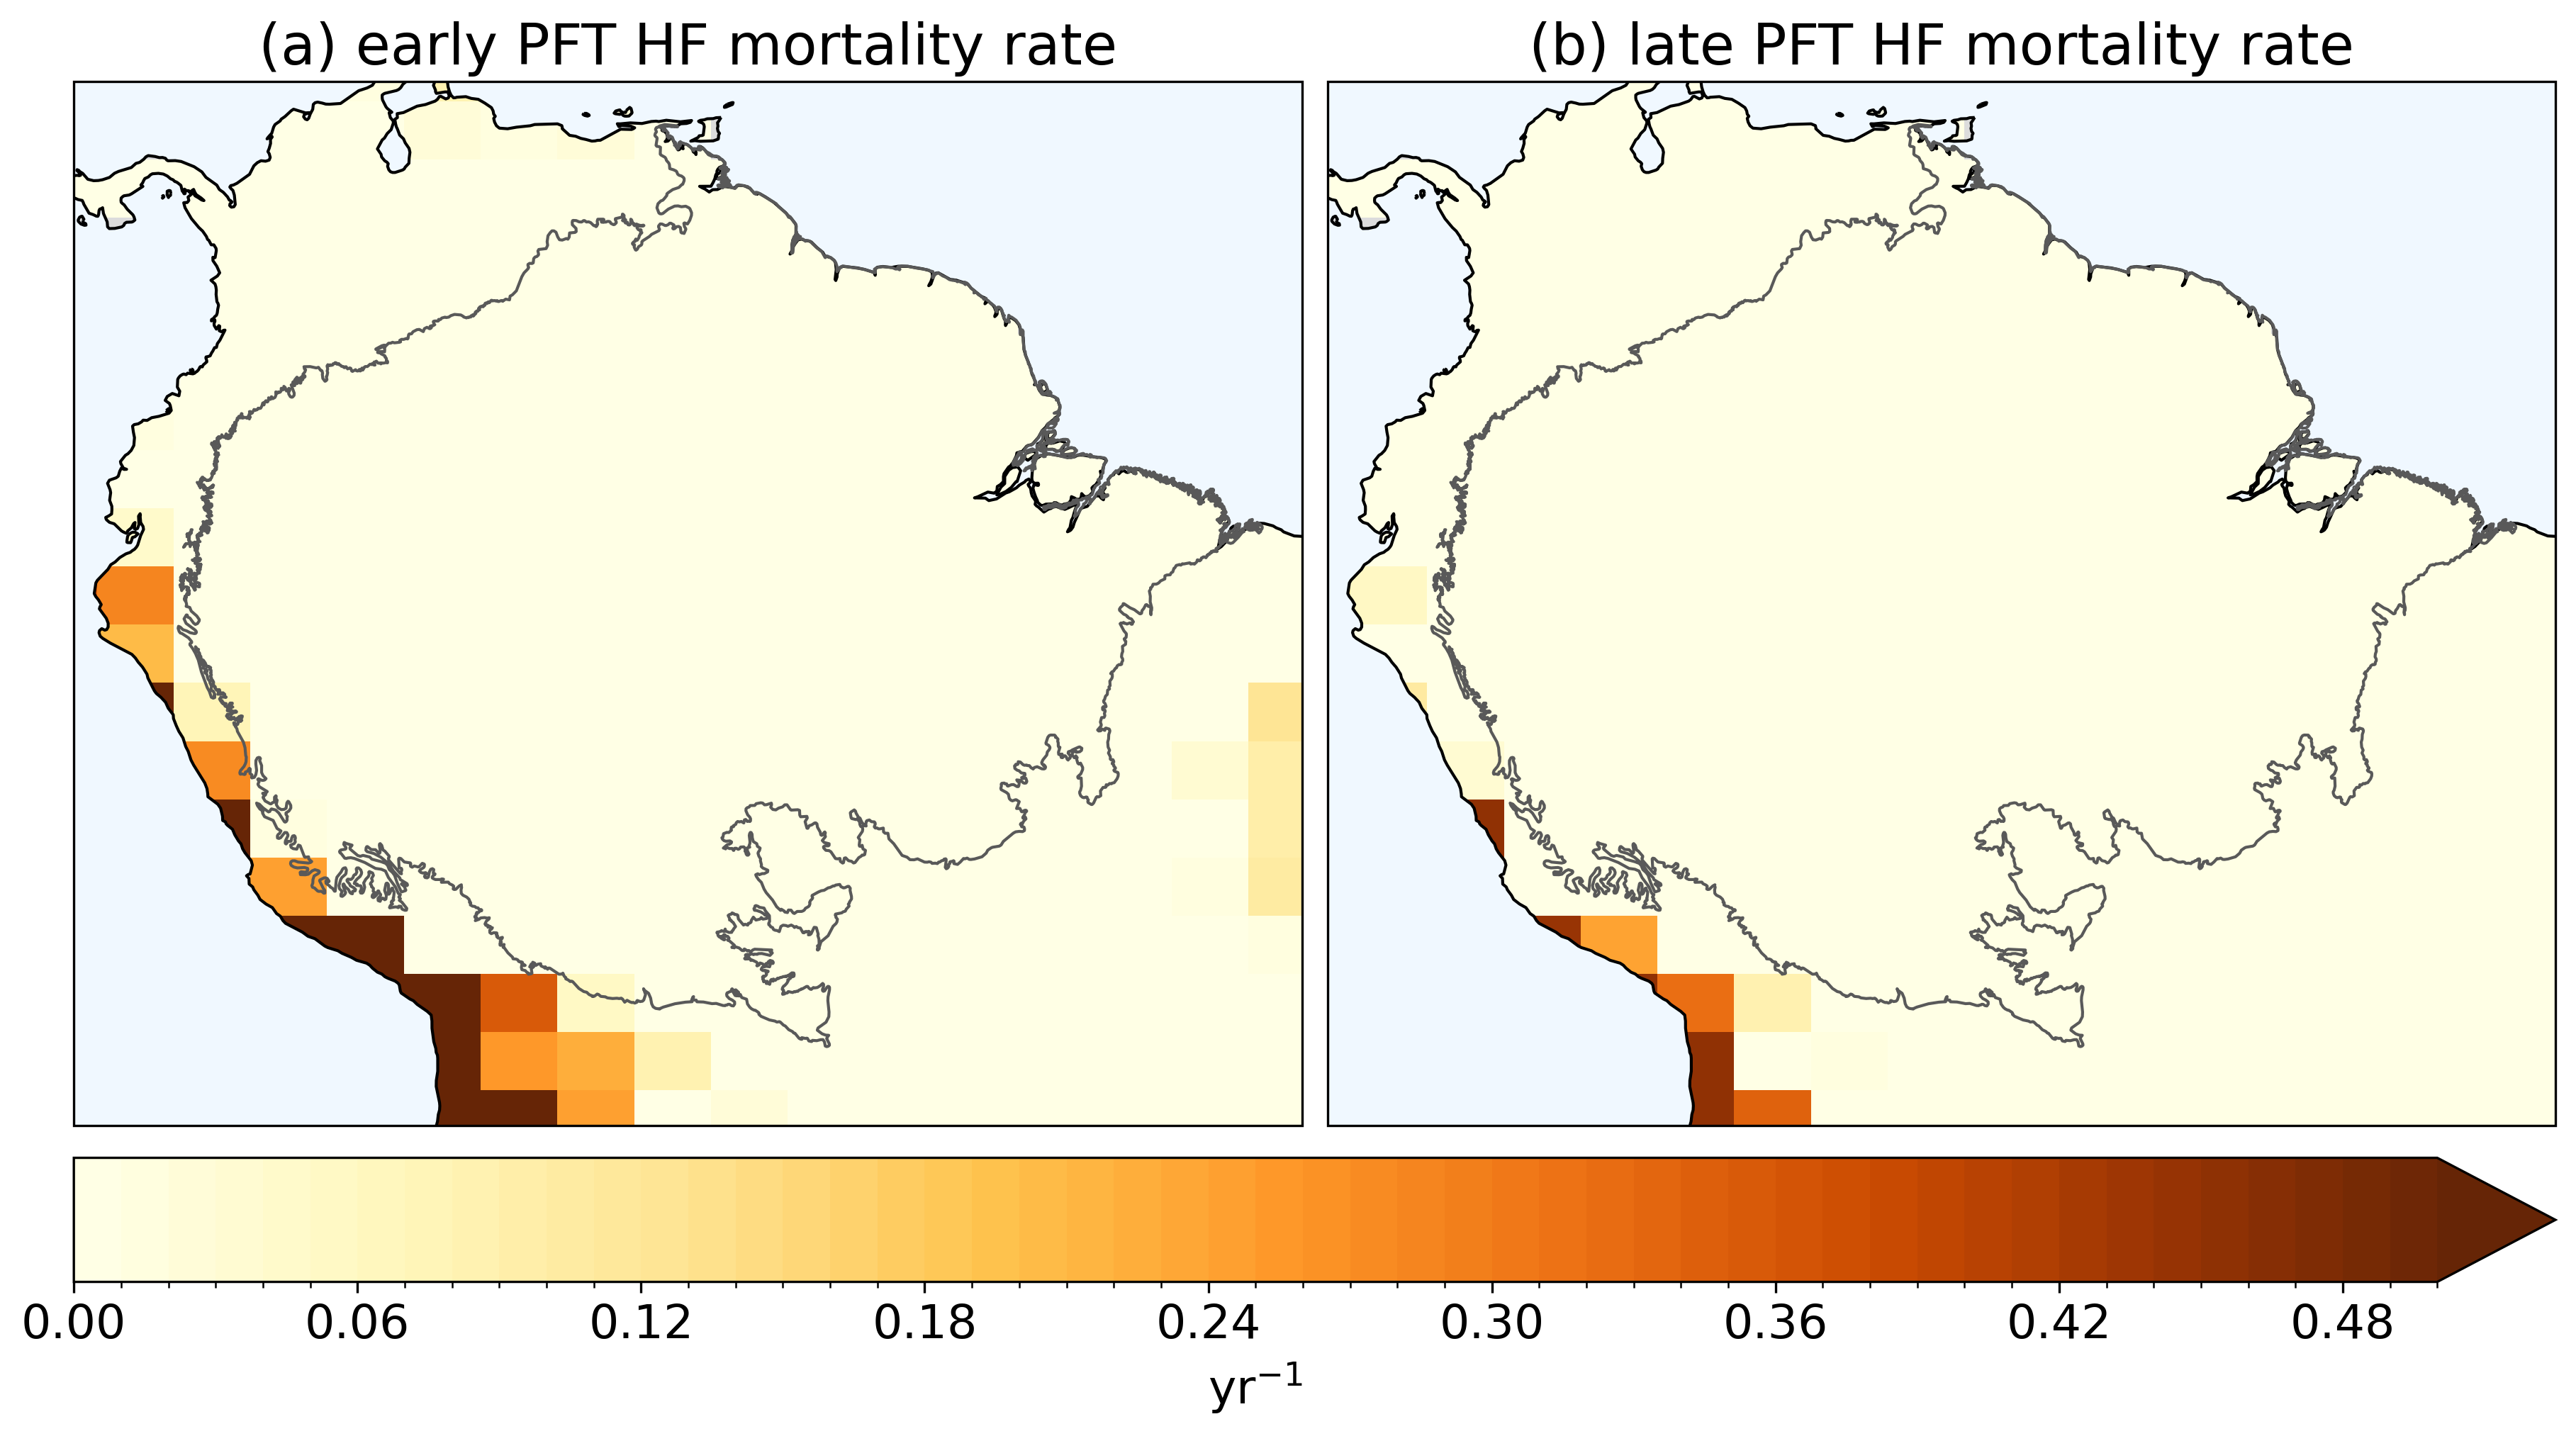

In [32]:
# Make a 2 panel figure for HF mortality

# Create figure with 2 subplots (1 row, 2 columns)
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 8),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)

ax1, ax2 = axes.flatten()

levels = np.linspace(0, 0.5, 51)

# First panel: early PFT
im1 = hf_mort_norm.isel(fates_levpft=0).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax1,
    add_colorbar=False,  # Turn off individual colorbar
)
ax1.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax1.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=1)
ax1.set_title("(a) early PFT HF mortality rate")
ax1.coastlines()
ax1.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax1.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax1.set_ylim([min_lat_plotting, max_lat_plotting])

# Second panel: late PFT
im2 = hf_mort_norm.isel(fates_levpft=1).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax2,
    add_colorbar=False,  # Turn off individual colorbar
)
ax2.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax2.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=1)
ax2.set_title("(b) late PFT HF mortality rate")
ax2.coastlines()
ax2.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax2.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax2.set_ylim([min_lat_plotting, max_lat_plotting])

# Add single shared colorbar spanning all subplots
cbar = fig.colorbar(
    im1,
    ax=axes,
    orientation="horizontal",
    shrink=1,
    pad=0.02,
    label="yr$^{-1}$",
)

In [33]:
fates

<xarray.Dataset>
Dimensions:                             (levgrnd: 15, levlak: 10, levdcmp: 15,
                                         levsoi: 10, fates_levscls: 13,
                                         fates_levscag: 91, fates_levscpf: 26,
                                         fates_levcacls: 2, fates_levcapf: 4,
                                         fates_levage: 7, fates_levpft: 2,
                                         fates_levlanduse: 5, fates_levfuel: 6,
                                         ...
                                         fates_levelage: 7,
                                         fates_levagefuel: 42,
                                         fates_levcdsc: 26, fates_levcdpf: 52,
                                         fates_levcdam: 2, time: 300,
                                         hist_interval: 2, lon: 24, lat: 23,
                                         fates_levlulu: 25, ltype: 9, natpft: 17)
Coordinates: (12/19)
  * levgrnd                             (levgrnd) float32 0.007101 ... 35.18
  * levlak                              (levlak) float32 0.05 0.6 ... 44.78
  * levdcmp                             (levdcmp) float32 0.007101 ... 35.18
  * levsoi                              (levsoi) float32 0.007101 ... 2.865
  * fates_levscls                       (fates_levscls) float32 0.0 ... 100.0
  * fates_levcacls                      (fates_levcacls) float32 0.0 5.0
    ...                                  ...
  * fates_levheight                     (fates_levheight) float32 0.0 ... 10.0
  * fates_levelem                       (fates_levelem) int32 1
  * fates_levcdam                       (fates_levcdam) float32 0.0 80.0
  * time                                (time) object 0001-02-01 00:00:00 ......
  * lon                                 (lon) float32 275.0 277.5 ... 332.5
  * lat                                 (lat) float32 -25.58 -23.68 ... 16.11
Dimensions without coordinates: fates_levscag, fates_levscpf, fates_levcapf,
                                fates_levcnlf, fates_levcnlfpf,
                                fates_levscagpf, fates_levagepft,
                                fates_levelpft, fates_levelcwd, fates_levelage,
                                fates_levagefuel, fates_levcdsc, fates_levcdpf,
                                hist_interval, fates_levlulu, ltype, natpft
Data variables: (12/656)
    fates_scmap_levscag                 (fates_levscag) int32 ...
    fates_agmap_levscag                 (fates_levscag) int32 ...
    fates_pftmap_levscpf                (fates_levscpf) int32 ...
    fates_scmap_levscpf                 (fates_levscpf) int32 ...
    fates_pftmap_levcapf                (fates_levcapf) int32 ...
    fates_camap_levcapf                 (fates_levcapf) int32 ...
    ...                                  ...
    WA                                  (time, lat, lon) float32 ...
    WASTEHEAT                           (time, lat, lon) float32 ...
    WIND                                (time, lat, lon) float32 ...
    ZBOT                                (time, lat, lon) float32 ...
    ZWT                                 (time, lat, lon) float32 ...
    ZWT_PERCH                           (time, lat, lon) float32 ...
Attributes: (12/28)
    title:                                     ELM History file information
    source:                                    E3SM Land Model
    source_id:                                 2d74f509c8
    product:                                   model-output
    realm:                                     land
    case:                                      hydro_comp_bmort_kmax_tune_sap...
    ...                                        ...
    ltype_deep_lake:                           5
    ltype_wetland:                             6
    ltype_urban_tbd:                           7
    ltype_urban_hd:                            8
    ltype_urban_md:                            9
    NCO:                                 